In [1]:
import squidpy as sq

import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

# load the H&E stained tissue image and crop to a smaller segment
img = sq.datasets.visium_hne_image_crop()
crop = img.crop_corner(0, 0, size=1000)


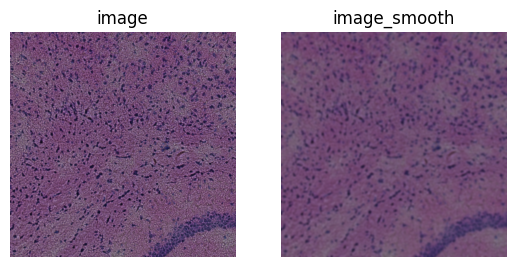

In [2]:
# smooth image
sq.im.process(crop, layer="image", method="smooth", sigma=4)

# plot the result
fig, axes = plt.subplots(1, 2)
for layer, ax in zip(["image", "image_smooth"], axes):
    crop.show(layer, ax=ax)
    ax.set_title(layer)

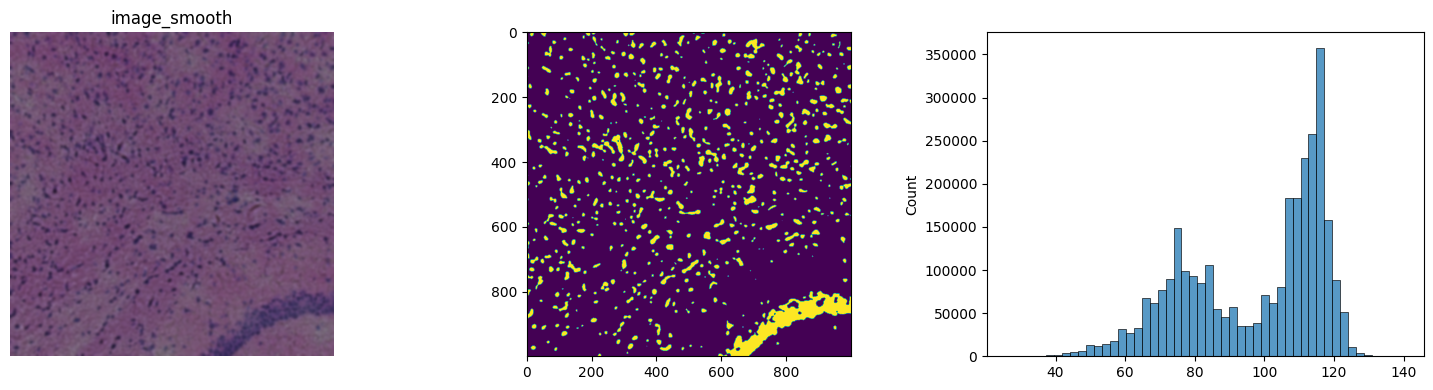

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
crop.show("image_smooth", cmap="gray", ax=axes[0])
axes[1].imshow(crop["image_smooth"][:, :, 0, 0] < 90)
_ = sns.histplot(np.array(crop["image_smooth"]).flatten(), bins=50, ax=axes[2])
plt.tight_layout()

In [8]:
sq.im.segment(img=crop, layer="image_smooth", layer_added="segmented_watershed", method="watershed", thresh=90, geq=False)

ImageContainer[shape=(1000, 1000), layers=['image', 'image_smooth', 'segmented_watershed']]
Number of segments in crop: 1182


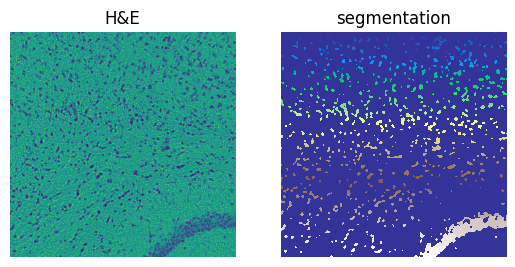

In [45]:
print(crop)
print(f"Number of segments in crop: {len(np.unique(crop['segmented_watershed']))}")

fig, axes = plt.subplots(1, 2)
crop.show("image", channel=0, ax=axes[0])
_ = axes[0].set_title("H&E")
crop.show("segmented_watershed", cmap="terrain", interpolation="none", ax=axes[1])
_ = axes[1].set_title("segmentation")

In [34]:
# this function doesn't return individual data except in the centroid array. 
seg_data = crop.features_segmentation(label_layer="segmented_watershed", 
                                       intensity_layer="image",
                                       props=["label", "area", "centroid", "eccentricity"],
                                       )
seg_data

{'segmentation_label': 1181,
 'segmentation_area_mean': 93.19729043183743,
 'segmentation_area_std': 150.06377710299068,
 'segmentation_centroid': array([[  4.79857643,  50.634905  ],
        [  4.37495329, 187.65924769],
        [  2.43047106, 204.29382275],
        ...,
        [990.04741022, 636.7650249 ],
        [993.1116113 , 650.76197912],
        [995.0145721 , 662.988489  ]]),
 'segmentation_eccentricity_mean': 0.669945113054943,
 'segmentation_eccentricity_std': 0.1878842862778699}

,centroid-0,centroid-1,label,eccentricity,area
0,5.186441,51.355932,1,0.594835,177.0
1,4.763889,188.041667,2,0.644868,144.0
2,2.824324,204.635135,3,0.716612,74.0
3,5.254335,304.179191,4,0.529493,173.0
4,4.424837,323.849673,5,0.796554,153.0


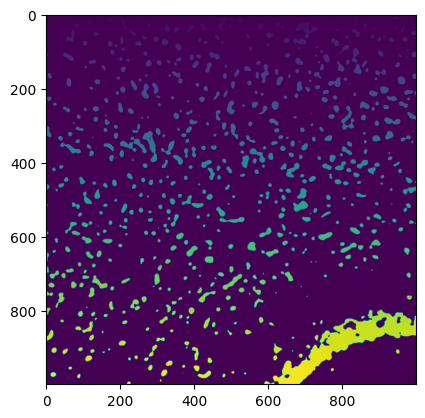

In [98]:
from skimage.measure import regionprops_table as rpt
import pandas as pd

plt.imshow(crop["segmented_watershed"].data[:,:,0,0])


im_feats = rpt(crop["segmented_watershed"].data[:,:,0,0], properties=('centroid',
                                                           'label',
                                                           'eccentricity', 
                                                           'area')
                )  

df = pd.DataFrame(im_feats)
df.head()

In [150]:
import anndata as ad

cents = df[["centroid-0", "centroid-1"]].to_numpy()

adata = ad.AnnData(obs=df[["label", "eccentricity", "area"]])
ct = np.random.choice(["muscle"], size=(adata.n_obs,))
adata.obs["cell_type"] = pd.Categorical(ct)  # Categoricals are preferred for efficiency
adata.obsm["spatial"] = cents
adata

/home/willow/miniconda3/envs/squid/lib/python3.10/site-packages/anndata/_core/anndata.py:117: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 1181 × 0
    obs: 'label', 'eccentricity', 'area', 'cell_type'
    obsm: 'spatial'

In [151]:
sq.gr.spatial_neighbors(adata, 
                        n_neighs=10, 
                        coord_type="generic")
adata

AnnData object with n_obs × n_vars = 1181 × 0
    obs: 'label', 'eccentricity', 'area', 'cell_type'
    uns: 'spatial_neighbors'
    obsm: 'spatial'
    obsp: 'spatial_connectivities', 'spatial_distances'

ERROR: Unable to fetch palette, reason: 'cell_type_colors'. Using `None`.


/home/willow/miniconda3/envs/squid/lib/python3.10/site-packages/squidpy/pl/_graph.py:307: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.lineplot(y="stats", x="bins", ci="sd", alpha=0.01, color="gray", data=res["sims_stat"], ax=ax)


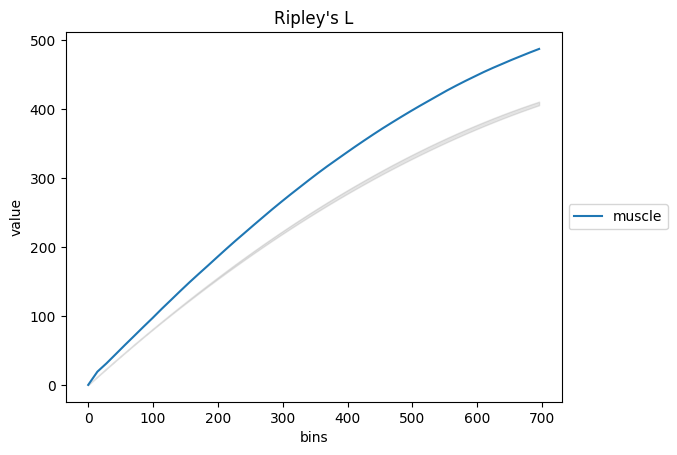

In [159]:
sq.gr.ripley(adata, cluster_key="cell_type", mode="L")
sq.pl.ripley(adata, cluster_key="cell_type", mode="L")

In [117]:
adata = sq.datasets.visium_fluo_adata()
adata

AnnData object with n_obs × n_vars = 2800 × 16562
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_MT', 'log1p_total_counts_MT', 'pct_counts_MT', 'n_counts', 'leiden', 'cluster'
    var: 'gene_ids', 'feature_types', 'genome', 'MT', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'spatial', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'